# 01 · Exploratory Data Analysis

**Goal:** understand the Telco customer base, how much churn there is, and which customer attributes
signal churn risk, so we can make informed decisions in the feature and modeling steps.

**Questions**
1. Is the data clean? (types, missing values, duplicates)
2. How imbalanced is the target?
3. How do tenure and charges relate to churn?
4. Which contract / service / billing attributes carry the most churn signal?
5. What does this mean for preprocessing and modeling?

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from churn.config import ID_COLUMN, REPORTS_DIR, TARGET
from churn.data.load import load_raw

sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 50)
FIG_DIR = REPORTS_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

df = load_raw()
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 1. Data quality

In [3]:
print("shape:", df.shape)
print("unique customer IDs:", df[ID_COLUMN].is_unique)
print("duplicate rows:", df.duplicated().sum())
print("missing values:", df.isna().sum().sum())
df.dtypes.to_frame("dtype").T

shape: (7043, 21)
unique customer IDs: True
duplicate rows: 0
missing values: 0


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
dtype,str,str,int64,str,str,int64,str,str,str,str,str,str,str,str,str,str,str,str,float64,str,str


`TotalCharges` should be numeric but is loaded as text. Let's find the values that fail to parse.

In [4]:
total_numeric = pd.to_numeric(df["TotalCharges"], errors="coerce")
bad = df.loc[total_numeric.isna(), [ID_COLUMN, "tenure", "MonthlyCharges", "TotalCharges", TARGET]]
print(f"{len(bad)} rows with non-numeric TotalCharges; values: {bad['TotalCharges'].unique().tolist()}")
bad

11 rows with non-numeric TotalCharges; values: [' ']


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


All of them have `tenure == 0`: brand-new customers who have not been billed yet. The blank is
logically **0**, not missing at random. *Preprocessing step: coerce to numeric and fill with 0.*

For the rest of the EDA we use a working copy with that fix and a binary target.

In [5]:
eda = df.copy()
eda["TotalCharges"] = total_numeric.fillna(0.0)
eda["churn"] = (eda[TARGET] == "Yes").astype(int)
eda["SeniorCitizen"] = eda["SeniorCitizen"].map({0: "No", 1: "Yes"})

NUMERIC = ["tenure", "MonthlyCharges", "TotalCharges"]
CATEGORICAL = [c for c in df.columns if c not in NUMERIC + [ID_COLUMN, TARGET]]
print("numeric:", NUMERIC)
print("categorical:", CATEGORICAL)
eda[NUMERIC].describe().T

numeric: ['tenure', 'MonthlyCharges', 'TotalCharges']
categorical: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


,count,mean,std,min,25%,50%,75%,max
tenure,7043.0,32.371149,24.559481,0.00,9.00,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.50,70.35,89.85,118.75
TotalCharges,7043.0,2279.734304,2266.794470,0.00,398.55,1394.55,3786.60,8684.80


## 2. Target balance

Churn
No     5174
Yes    1869

churn rate: 26.5%


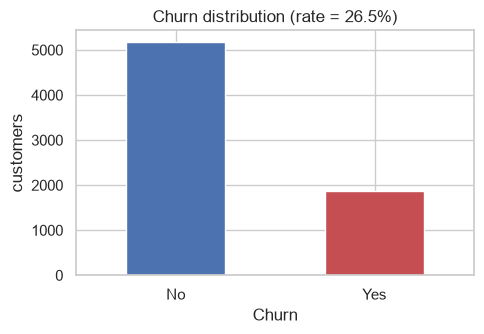

In [6]:
counts = eda[TARGET].value_counts()
rate = eda["churn"].mean()
print(counts.to_string())
print(f"\nchurn rate: {rate:.1%}")

ax = counts.plot.bar(rot=0, color=["#4c72b0", "#c44e52"], figsize=(5, 3.5))
ax.set_title(f"Churn distribution (rate = {rate:.1%})")
ax.set_ylabel("customers")
plt.tight_layout()
plt.savefig(FIG_DIR / "01_target_balance.png", dpi=120)
plt.show()

About 1 in 4 customers churned. This is a moderate imbalance, so accuracy is misleading: always
predicting "No" scores about 73%. We will evaluate with **recall, precision, F1 and PR-AUC** and
use a stratified train/test split.

## 3. Numeric features vs churn

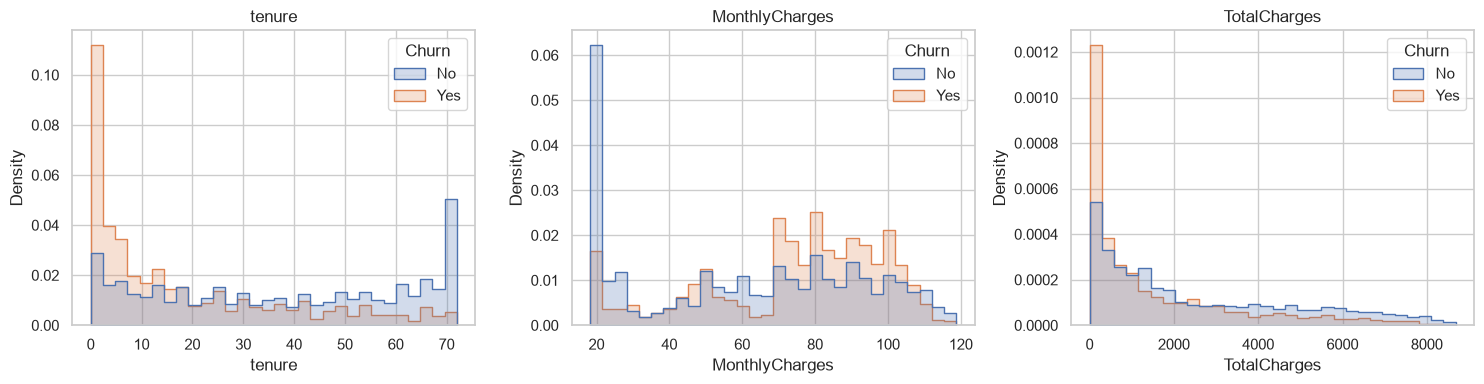

,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,38.0,64.425,1679.525
Yes,10.0,79.650,703.550


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, NUMERIC):
    sns.histplot(data=eda, x=col, hue=TARGET, bins=30, stat="density",
                 common_norm=False, element="step", ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.savefig(FIG_DIR / "01_numeric_distributions.png", dpi=120)
plt.show()

eda.groupby(TARGET)[NUMERIC].median()

Churn rate by tenure band. This matters most for an *early-warning* system, because it shows
**when** in the customer lifecycle the risk is highest.

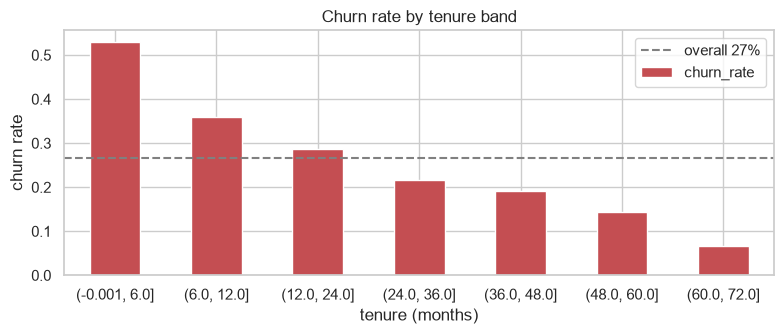

,churn_rate,customers
tenure_band,,
"(-0.001, 6.0]",52.9%,1481
"(6.0, 12.0]",35.9%,705
"(12.0, 24.0]",28.7%,1024
"(24.0, 36.0]",21.6%,832
"(36.0, 48.0]",19.0%,762
"(48.0, 60.0]",14.4%,832
"(60.0, 72.0]",6.6%,1407


In [8]:
bands = [0, 6, 12, 24, 36, 48, 60, 72]
eda["tenure_band"] = pd.cut(eda["tenure"], bins=bands, include_lowest=True)
by_band = eda.groupby("tenure_band", observed=True)["churn"].agg(["mean", "size"])
by_band.columns = ["churn_rate", "customers"]

ax = by_band["churn_rate"].plot.bar(rot=0, figsize=(8, 3.5), color="#c44e52")
ax.axhline(rate, ls="--", c="grey", label=f"overall {rate:.0%}")
ax.set_ylabel("churn rate"); ax.set_xlabel("tenure (months)"); ax.legend()
ax.set_title("Churn rate by tenure band")
plt.tight_layout()
plt.savefig(FIG_DIR / "01_churn_by_tenure.png", dpi=120)
plt.show()
by_band.style.format({"churn_rate": "{:.1%}"})

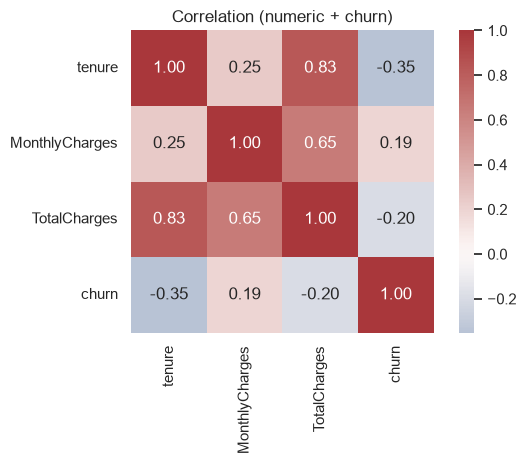

In [9]:
corr = eda[NUMERIC + ["churn"]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, square=True)
plt.title("Correlation (numeric + churn)")
plt.tight_layout()
plt.show()

`TotalCharges` is close to `tenure × MonthlyCharges`, so it is highly correlated with tenure. Linear
models will see this collinearity, and tree models will mostly ignore it. Let's check how close the
approximation is.

In [10]:
approx = eda["tenure"] * eda["MonthlyCharges"]
rel_err = ((eda["TotalCharges"] - approx).abs() / approx.replace(0, np.nan)).median()
print(f"median relative gap between TotalCharges and tenure*MonthlyCharges: {rel_err:.1%}")

median relative gap between TotalCharges and tenure*MonthlyCharges: 2.0%


## 4. Categorical features vs churn

In [11]:
rows = []
for col in CATEGORICAL:
    g = eda.groupby(col)["churn"].agg(["mean", "size"])
    for level, (m, n) in g.iterrows():
        rows.append({"feature": col, "level": level, "churn_rate": m, "customers": n})
cat_rates = pd.DataFrame(rows)

# Rank features by spread between their highest- and lowest-churn level
spread = (cat_rates.groupby("feature")["churn_rate"].agg(lambda s: s.max() - s.min())
          .sort_values(ascending=False).rename("churn_rate_spread"))
spread.to_frame().style.format("{:.1%}").bar(color="#c44e52")

,churn_rate_spread
feature,
Contract,39.9%
InternetService,34.5%
OnlineSecurity,34.4%
TechSupport,34.2%
OnlineBackup,32.5%
DeviceProtection,31.7%
PaymentMethod,30.0%
StreamingMovies,26.3%
StreamingTV,26.1%


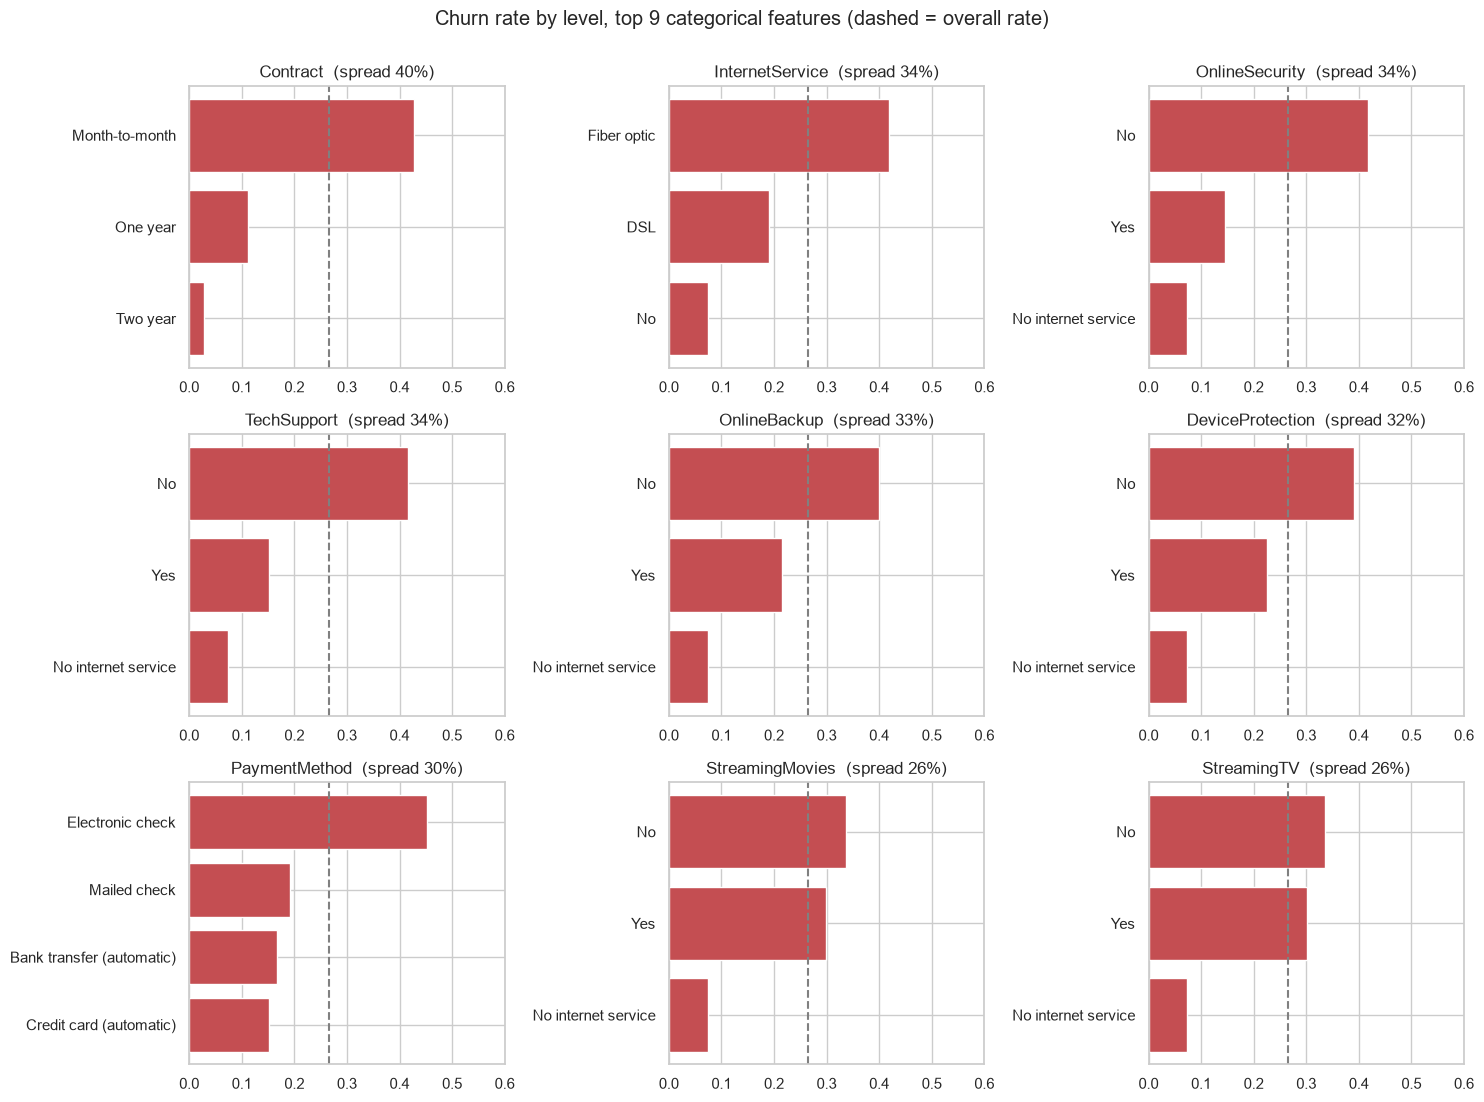

In [12]:
top = spread.index[:9]
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for ax, col in zip(axes.flat, top):
    d = cat_rates[cat_rates.feature == col].sort_values("churn_rate", ascending=False)
    ax.barh(d["level"].astype(str), d["churn_rate"], color="#c44e52")
    ax.axvline(rate, ls="--", c="grey")
    ax.set_title(f"{col}  (spread {spread[col]:.0%})")
    ax.set_xlim(0, 0.6)
    ax.invert_yaxis()
plt.suptitle("Churn rate by level, top 9 categorical features (dashed = overall rate)", y=1.0)
plt.tight_layout()
plt.savefig(FIG_DIR / "01_categorical_churn_rates.png", dpi=120)
plt.show()

**Redundant levels.** "No internet service" shows up in six add-on columns and "No phone service" in
`MultipleLines`. Each one only repeats `InternetService == "No"` / `PhoneService == "No"`.

In [13]:
addons = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport",
          "StreamingTV", "StreamingMovies"]
no_inet = eda["InternetService"] == "No"
print("'No internet service' rows match InternetService == 'No' exactly:",
      all(((eda[c] == "No internet service") == no_inet).all() for c in addons))
print("'No phone service' rows match PhoneService == 'No' exactly:",
      ((eda["MultipleLines"] == "No phone service") == (eda["PhoneService"] == "No")).all())

'No internet service' rows match InternetService == 'No' exactly: True
'No phone service' rows match PhoneService == 'No' exactly: True


**Engineered-feature check.** Does the *number* of add-on services relate to churn? Protective
add-ons such as security and tech support may behave differently from streaming.

In [14]:
eda["n_addons"] = (eda[addons] == "Yes").sum(axis=1)
inet = eda[~no_inet]
(inet.groupby("n_addons")["churn"].agg(churn_rate="mean", customers="size")
     .style.format({"churn_rate": "{:.1%}"}))

,churn_rate,customers
n_addons,,
0,52.2%,693
1,45.8%,966
2,35.8%,1033
3,27.4%,1118
4,22.3%,852
5,12.4%,571
6,5.3%,284


## 5. Interaction: contract × tenure

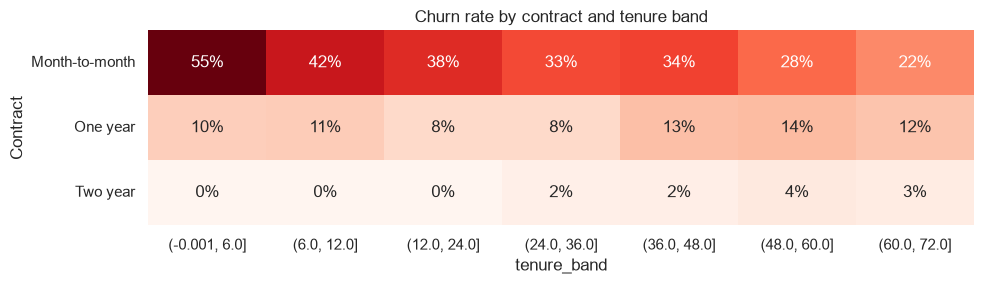

In [15]:
pivot = eda.pivot_table(index="Contract", columns="tenure_band", values="churn",
                        aggfunc="mean", observed=True)
plt.figure(figsize=(10, 3))
sns.heatmap(pivot, annot=True, fmt=".0%", cmap="Reds", cbar=False)
plt.title("Churn rate by contract and tenure band")
plt.tight_layout()
plt.savefig(FIG_DIR / "01_contract_x_tenure.png", dpi=120)
plt.show()

## 6. Summary and implications

### Key findings
| # | Finding | Evidence |
|---|---------|----------|
| 1 | **Data is clean except `TotalCharges`**: 11 blanks, all `tenure == 0` (not yet billed) | no NaNs, no duplicates, unique IDs |
| 2 | **Moderate imbalance**: 26.5% churn (1,869 / 7,043) | a model that always says "No" gets about 73% accuracy |
| 3 | **Churn is concentrated early in the lifecycle**: 53% in the first 6 months vs 7% after 5 years | median tenure 10 (churners) vs 38 (stayers) |
| 4 | **Contract is the strongest single driver**: month-to-month 43%, one-year 11%, two-year 3% | month-to-month stays above 20% churn at every tenure |
| 5 | **Fiber optic customers churn more** (42% vs 19% DSL), and churners pay more per month (median 80 vs 64) | possible price or quality issue with fiber |
| 6 | **Protective add-ons are associated with retention**: no OnlineSecurity / TechSupport means about 42% churn vs about 15% with them | streaming add-ons barely matter (34% vs 30%) |
| 7 | **Electronic check payers churn at 45%**, about 3× the automatic payment methods | paperless billing, senior citizens, and customers without partner or dependents are also higher risk |
| 8 | **Weak signal:** `gender`, `PhoneService`, `MultipleLines` (spread under 4 points) | candidates to drop |

### Implications for the next steps
- **Cleaning:** coerce `TotalCharges` to numeric and fill blanks with 0. Map `Churn` to 1/0. Drop `customerID` from features but keep it for API responses.
- **Encoding:** one-hot encode the categoricals. "No internet service" / "No phone service" exactly duplicate `InternetService` / `PhoneService`, so they can be collapsed to "No" without losing information.
- **Collinearity:** `TotalCharges` ≈ `tenure × MonthlyCharges` (2% median gap; correlation with tenure 0.83). Fine for trees. For linear models, consider dropping it or using regularization.
- **Candidate engineered features:** number of protective add-ons, a tenure band / `is_new_customer` flag, `is_month_to_month`, `auto_payment`. Validate them with the model rather than assuming they help.
- **Evaluation:** stratified split, and optimize for **recall / PR-AUC** on the churn class. The decision threshold should reflect the business cost of a missed churner vs an unnecessary retention offer.
- **Early-warning angle:** new month-to-month customers are the highest-risk segment, so the API should score customers from their first month.